In [10]:
import pandas as pd
import matplotlib as plt
import seaborn as sns
pvd = pd.read_excel('data/pvdstudy.xlsx')
pvd.head()
pvd.describe

<bound method NDFrame.describe of      L.P.  Participant code  Pregnancy meeting  Stress scale  Stress1  \
0       1                 1                NaN           NaN        2   
1       2                 2                NaN           NaN        3   
2       3                 3                NaN           NaN        1   
3       4                 4                NaN           NaN        4   
4       5                 5                NaN           NaN        3   
..    ...               ...                ...           ...      ...   
195   196               217                NaN           NaN        1   
196   197               218                NaN           NaN        1   
197   198               219                NaN           NaN        2   
198   199               220                NaN           NaN        0   
199   200               221                NaN           NaN        1   

     Stress2  Stress3  Stress4  Stress5  Stress6  ...  PVD9.1  PVD10.1  \
0          2   

In [7]:
#Elijah - Which life circumstances best predict pregnant women's stress: economic status, relationship stability, or whether the pregnancy was planned?

In [11]:

pvd_cols = ['SUM (0-40)','Income (1 - below 600, 2 - 600 - 1000, 3- 1000 - 1500, 4 - 1500 - 2000, 5 - 2000 - 3000, 6 - 3000 - 4000, 7 - 4000 - 6000, 8 - over 6000 PLN)','SES self-assessment (1very poor to 7very good)', 'Pregnancy planned (1Y)','Relationship status (1single, 2cohabiting, 3married)', 'Relationship with a biological father of a child']


In [12]:
pvd_clean = pvd[pvd_cols].copy()
pvd_clean

,SUM (0-40),"Income (1 - below 600, 2 - 600 - 1000, 3- 1000 - 1500, 4 - 1500 - 2000, 5 - 2000 - 3000, 6 - 3000 - 4000, 7 - 4000 - 6000, 8 - over 6000 PLN)",SES self-assessment (1very poor to 7very good),Pregnancy planned (1Y),"Relationship status (1single, 2cohabiting, 3married)",Relationship with a biological father of a child
0,20,4,6,1,3,1
1,31,2,4,1,3,1
2,13,5,5,0,3,1
3,20,5,3,1,3,1
4,24,3,4,1,3,1
...,...,...,...,...,...,...
195,13,5,4,1,3,1
196,17,4,4,0,2,1
197,15,6,5,1,3,1
198,1,5,4,1,3,1


In [13]:
stress = ['SUM (0-40)']

In [14]:
Relationship = ['Relationship status (1single, 2cohabiting, 3married)' ]

In [15]:
father = ['Relationship with a biological father of a child']

In [16]:
income = 'Income (1 - below 600, 2 - 600 - 1000, 3- 1000 - 1500, 4 - 1500 - 2000, 5 - 2000 - 3000, 6 - 3000 - 4000, 7 - 4000 - 6000, 8 - over 6000 PLN)'

In [17]:
planned = ['Pregnancy planned (1Y)']

In [18]:
pvd_clean['income_band'] = pd.cut(
    pvd_clean[income],
    bins=[0, 3, 5, 8],
    labels=['Low', 'Middle', 'High']
)


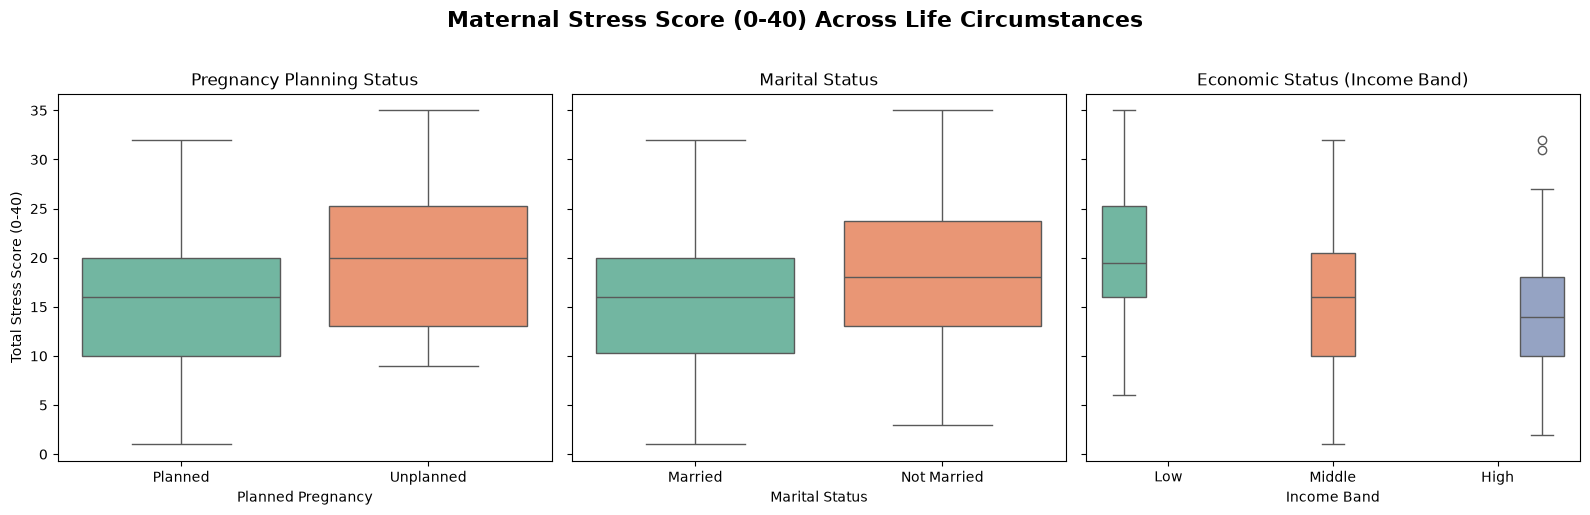

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create clean binary/categorical columns for clear plotting labels
pvd_clean['planned_label'] = pvd_clean['Pregnancy planned (1Y)'].map(
    {1: 'Planned', 0: 'Unplanned'}
)
pvd_clean['married_label'] = pvd_clean[
    'Relationship status (1single, 2cohabiting, 3married)'
].map(lambda x: 'Married' if x == 3 else 'Not Married')

# Set up 1 row, 3 columns multi-panel figure
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
fig.suptitle(
    'Maternal Stress Score (0-40) Across Life Circumstances',
    fontsize=16,
    fontweight='bold',
    y=1.02,
)

# Panel 1: Stress by Planned/Unplanned
sns.boxplot(
    ax=axes[0],
    data=pvd_clean,
    x='planned_label',
    y='SUM (0-40)',
    hue='planned_label',
    palette='Set2',
    legend=False,
)
axes[0].set_title('Pregnancy Planning Status')
axes[0].set_xlabel('Planned Pregnancy')
axes[0].set_ylabel('Total Stress Score (0-40)')

# Panel 2: Stress by Married / Not Married
sns.boxplot(
    ax=axes[1],
    data=pvd_clean,
    x='married_label',
    y='SUM (0-40)',
    hue='married_label',
    palette='Set2',
    legend=False,
)
axes[1].set_title('Marital Status')
axes[1].set_xlabel('Marital Status')
axes[1].set_ylabel('')  # Shared y-axis

# Panel 3: Stress by Income Band
sns.boxplot(
    ax=axes[2],
    data=pvd_clean,
    x='income_band',
    y='SUM (0-40)',
    hue='income_band',
    palette='Set2',
    order=['Low', 'Middle', 'High'],
    legend=False,
)
axes[2].set_title('Economic Status (Income Band)')
axes[2].set_xlabel('Income Band')
axes[2].set_ylabel('')  # Shared y-axis

plt.tight_layout()
plt.show()

## Research Question Analysis & Proposal Plan

### 1. Variables & Data Preparation
- **Outcome Variable:** Total Stress Score (`SUM (0-40)`).
- **Predictors:** Financial Status (`SES self-assessment` / `income_band`), Pregnancy Planning (`planned_label`), and Relationship Status (`married_label`).
- **Wrangling Applied:** Mapped categorical indicators into clean text labels (`Planned`/`Unplanned`, `Married`/`Not Married`) and binned numeric income into broad ordinal tiers (`Low`, `Middle`, `High`).

### 2. Exploratory Findings (First-Look Boxplots)
- Unplanned pregnancies exhibit noticeably higher median stress scores compared to planned pregnancies.
- Lower income tiers show elevated median stress scores relative to middle and high income groups.
- Unmarried participants display slightly higher median stress scores than married participants.

### 3. Analysis Plan & Next Steps
- **Multiple Regression Analysis:** To determine which life circumstance is the primary independent driver of stress, we will fit a multiple linear regression combining financial status, pregnancy planning, and relationship status. This will isolate the effect of each factor while controlling for the others.
- **Step Beyond FDS I:** We plan to implement a **train/test split (held-out data evaluation)** to assess how accurately a model trained on these baseline life circumstances can predict high vs. low maternal stress levels on unseen data.

### 4. Expected Outcomes
- **If Hunch is Supported:** Financial status / lower income will demonstrate the largest standardized effect ($\beta$) on stress scores when holding pregnancy planning and marital status constant.
- **If Hunch is Wrong:** Pregnancy planning status or marital status will retain a larger significant association with stress scores than income once all variables are evaluated together in the multiple regression model.